# 28｜小样本模板：快速起步与边界

目标：从真实零件图裁一个模板，在原图中找位置，并看到旋转、尺度变化的影响。模板匹配适合外观、角度和尺度受控的定位原型；匹配分数不是缺陷概率，更不是焊接合格概率。

参考：[OpenCV 模板匹配](https://docs.opencv.org/4.x/d4/dc6/tutorial_py_template_matching.html)。下面模板来自同一张图，属于自匹配演示，不能作为独立测试。

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "course_utils.py").is_file())
INDUSTRIAL_ROOT = ROOT / "courses" / "industrial-vision-lab"
if str(INDUSTRIAL_ROOT) not in sys.path:
    sys.path.insert(0, str(INDUSTRIAL_ROOT))
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
import lab_utils as lab
print("OpenCV", cv2.__version__, "| NumPy", np.__version__)

OpenCV 4.12.0 | NumPy 2.2.6


/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 20154 (\N{CJK UNIFIED IDEOGRAPH-4EBA}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 24037 (\N{CJK UNIFIED IDEOGRAPH-5DE5}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 35009 (\N{CJK UNIFIED IDEOGRAPH-88C1}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 20986 (\N{CJK UNIFIED IDEOGRAPH-51FA}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/

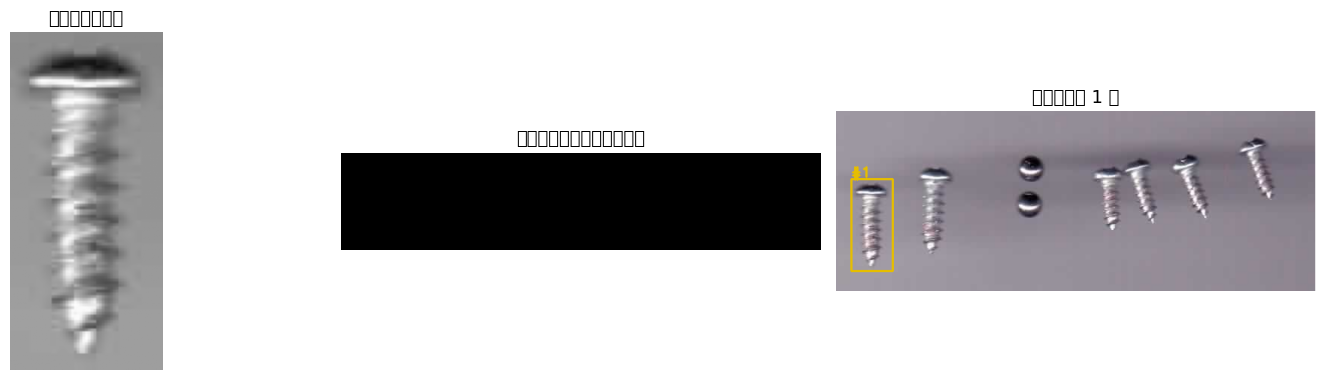

最大自匹配相似度 0.9999980330467224


In [2]:
image = lab.load_case("parts_separated")
g = lab.gray(image)
# 人工查看本公开照片后选第一颗螺钉的完整窗口，xyxy，像素单位。
x1, y1, x2, y2 = 20, 90, 75, 212
template = g[y1:y2, x1:x2]
assert template.size and template.std() > 1
scores = cv2.matchTemplate(g, template, cv2.TM_CCOEFF_NORMED)
matches = lab.suppress_matches(scores, template.shape, threshold=0.80)
lab.show_images([template, scores, lab.draw_boxes(image, matches)],
                ["人工裁出的模板", "位置相似度热图（非概率）", f"自匹配候选 {len(matches)} 处"], cols=3)
print("最大自匹配相似度", cv2.minMaxLoc(scores)[1])

## 1. 限制重复框

相邻位置会得到相近分数，因此需要空间抑制，避免一颗螺钉输出很多重叠框。本课做简单中心邻域抑制；它不处理可变尺度重叠的全部情况。实际系统应记录原图尺寸和目标框的坐标系。

/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 27966 (\N{CJK UNIFIED IDEOGRAPH-6D3E}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 29983 (\N{CJK UNIFIED IDEOGRAPH-751F}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 26059 (\N{CJK UNIFIED IDEOGRAPH-65CB}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 36716 (\N{CJK UNIFIED IDEOGRAPH-8F6C}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 65292 (\N{FULLWIDTH COMMA}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-begin

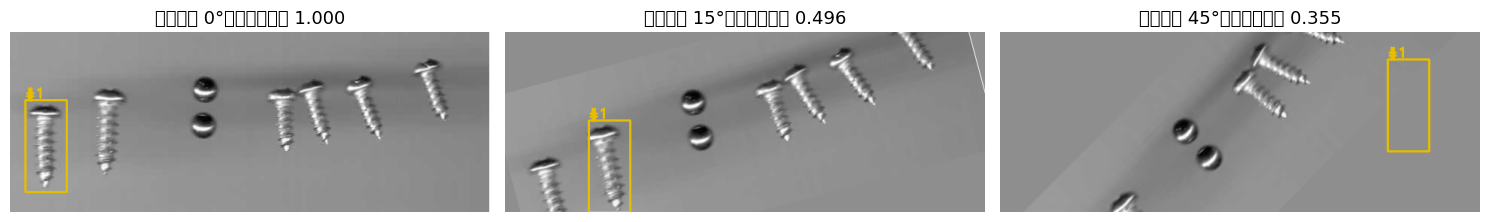

In [3]:
views, captions = [], []
for angle in [0, 15, 45]:
    matrix = cv2.getRotationMatrix2D((g.shape[1] / 2, g.shape[0] / 2), angle, 1)
    rotated = cv2.warpAffine(g, matrix, (g.shape[1], g.shape[0]), borderValue=int(np.median(g)))
    result = cv2.matchTemplate(rotated, template, cv2.TM_CCOEFF_NORMED)
    _, value, _, point = cv2.minMaxLoc(result)
    row = {"bbox": [point[0], point[1], template.shape[1], template.shape[0]], "status": "REVIEW"}
    views.append(lab.draw_boxes(rotated, [row]))
    captions.append(f"派生旋转 {angle}°，最高相似度 {value:.3f}")
lab.show_images(views, captions, cols=3)

## 2. 什么时候应停止堆模板

如果同一位置因打光、反光、旋转反复变样，先处理采集条件与工件对齐。模板可用于定位已知汇流排轮廓，但不能凭一张模板证明镍片焊接状态。对于多型号，应把相同尺寸零件的定位与具体配方规则分开。

要评估泛化，需把同一物理零件、同一视频连续帧及其所有增强保持在同一组。旋转、调亮、换背景不能增加独立来源数。当前自匹配分数绝不填入“准确率”。

## 来源与练习边界

公开焊缝：sukmaadhiwijaya / rikkarth，固定提交 `8b80d1afe88c0b946500a498cbdb9d7a1eda5533`，数据卡声明 CC0-1.0；工业表面：Kolektor Group / ViCoS，CC BY-NC-SA 4.0；分散零件：Tung1213，CC BY-SA 3.0；重叠零件：Technologyfelix，CC BY-SA 4.0。相关照片和派生图保留原许可及署名。

完整来源、原许可页、下载路径及 SHA256 见 [DATA_SOURCES.md](../DATA_SOURCES.md) 和 [source_manifest.json](../sources/source_manifest.json)。本课是非商业教学。灰度、二值、叠框及扰动均为原照片的派生图，七格合成图另有醒目标记。它们不等于新增独立验收数据，也不证明电池焊接准确率或机械强度。